In [1]:
import os

print(os.listdir("/content"))

['.config', 'dataset.csv', 'sample_data']


In [2]:

import pandas as pd

employee_data = pd.read_csv("/content/dataset.csv")

print("Dataset Overview")
print("-" * 40)
print("Number of records:", employee_data.shape[0])
print("Number of columns:", employee_data.shape[1])

print("\nColumn Names:")
print(employee_data.columns.tolist())

print("\nFirst Five Records:")
display(employee_data.head())

print("\nData Types:")
print(employee_data.dtypes)

print("\nMissing Values:")
print(employee_data.isnull().sum())

print("\nDuplicate Rows:", employee_data.duplicated().sum())


Dataset Overview
----------------------------------------
Number of records: 5000
Number of columns: 8

Column Names:
['emp_id', 'department', 'grade', 'join_date', 'monthly_salary_inr', 'leave_days_taken', 'performance_score', 'attrition']

First Five Records:


,emp_id,department,grade,join_date,monthly_salary_inr,leave_days_taken,performance_score,attrition
0,EMP0001,Sales,L5,2026-01-25,123614.0,5,2.7,0
1,EMP0002,Sales,L2,2024-12-17,40932.0,2,3.9,0
2,EMP0003,Engineering,L1,2024-05-24,111603.0,4,4.0,0
3,EMP0004,Operations,L4,2025-04-01,167310.0,2,4.1,0
4,EMP0005,Engineering,L1,2024-03-27,105169.0,13,2.5,0



Data Types:
emp_id                 object
department             object
grade                  object
join_date              object
monthly_salary_inr    float64
leave_days_taken        int64
performance_score     float64
attrition               int64
dtype: object

Missing Values:
emp_id                0
department            0
grade                 0
join_date             0
monthly_salary_inr    0
leave_days_taken      0
performance_score     0
attrition             0
dtype: int64

Duplicate Rows: 0


In [3]:

required_columns = [
    "emp_id",
    "department",
    "grade",
    "join_date",
    "monthly_salary_inr",
    "leave_days_taken",
    "performance_score",
    "attrition"
]

print("Correct column structure:", list(employee_data.columns) == required_columns)
print("Unique employee IDs:", employee_data["emp_id"].nunique())
print("Missing values:", employee_data.isnull().sum().sum())
print("Duplicate rows:", employee_data.duplicated().sum())

print("\nNumeric column summary:")
display(
    employee_data[
        [
            "monthly_salary_inr",
            "leave_days_taken",
            "performance_score",
            "attrition"
        ]
    ].describe()
)

print("\nDepartment count:", employee_data["department"].nunique())
print("\nDepartment distribution:")
display(employee_data["department"].value_counts())

print("\nGrade distribution:")
display(employee_data["grade"].value_counts())

print("\nAttrition values:")
display(employee_data["attrition"].value_counts(dropna=False))

print("\nJoin date range:")
print(employee_data["join_date"].min(), "to", employee_data["join_date"].max())


Correct column structure: True
Unique employee IDs: 5000
Missing values: 0
Duplicate rows: 0

Numeric column summary:


,monthly_salary_inr,leave_days_taken,performance_score,attrition
count,5000.00000,5000.000000,5000.000000,5000.00000
mean,92639.40264,8.310400,3.476180,0.11860
std,49146.18825,4.498811,0.782494,0.32335
min,22023.32000,0.000000,1.000000,0.00000
25%,50106.42500,6.000000,2.900000,0.00000
50%,83122.98500,8.000000,3.500000,0.00000
75%,125747.29000,10.000000,4.000000,0.00000
max,219924.68000,30.000000,5.000000,1.00000



Department count: 10

Department distribution:


,count
department,
Engineering,829
Operations,718
Sales,673
IT,556
Finance,500
Customer Support,469
Marketing,413
HR,383
Research & Development,282



Grade distribution:


,count
grade,
L1,1106
L2,1101
L3,1030
L4,1029
L5,734



Attrition values:


,count
attrition,
0,4407
1,593



Join date range:
2024-01-01 to 2026-12-31


In [4]:

import pandas as pd

employee_data = pd.read_csv("/content/dataset.csv")

required_columns = [
    "emp_id",
    "department",
    "grade",
    "join_date",
    "monthly_salary_inr",
    "leave_days_taken",
    "performance_score",
    "attrition"
]

employee_data = employee_data[required_columns].copy()

for column in ["emp_id", "department", "grade"]:
    employee_data[column] = (
        employee_data[column].astype("string").str.strip()
    )

employee_data["join_date"] = pd.to_datetime(
    employee_data["join_date"], errors="coerce"
)

numeric_columns = [
    "monthly_salary_inr",
    "leave_days_taken",
    "performance_score",
    "attrition"
]

for column in numeric_columns:
    employee_data[column] = pd.to_numeric(
        employee_data[column], errors="coerce"
    )

valid_records = (
    employee_data["emp_id"].notna()
    & employee_data["emp_id"].ne("")
    & employee_data["department"].notna()
    & employee_data["department"].ne("")
    & employee_data["grade"].notna()
    & employee_data["grade"].ne("")
    & employee_data["join_date"].notna()
    & employee_data["monthly_salary_inr"].gt(0)
    & employee_data["leave_days_taken"].between(0, 365)
    & employee_data["performance_score"].between(1, 5)
    & employee_data["attrition"].isin([0, 1])
)

cleaned_data = employee_data.loc[valid_records].copy()
cleaned_data = cleaned_data.drop_duplicates()
cleaned_data = cleaned_data.drop_duplicates(
    subset="emp_id", keep="first"
)

cleaned_data["join_date"] = (
    cleaned_data["join_date"].dt.strftime("%Y-%m-%d")
)

cleaned_data.to_csv(
    "/content/cleaned_dataset.csv", index=False
)

print("Original records:", len(employee_data))
print("Cleaned records:", len(cleaned_data))
print("Records excluded:", len(employee_data) - len(cleaned_data))
print("Missing values remaining:", cleaned_data.isnull().sum().sum())
print("Duplicate employee IDs:", cleaned_data["emp_id"].duplicated().sum())
print("Cleaned dataset saved successfully.")


Original records: 5000
Cleaned records: 5000
Records excluded: 0
Missing values remaining: 0
Duplicate employee IDs: 0
Cleaned dataset saved successfully.


In [5]:
import pandas as pd

employee_data = pd.read_csv("/content/cleaned_dataset.csv")

print("Dataset shape:", employee_data.shape)
display(employee_data.head())

Dataset shape: (5000, 8)


,emp_id,department,grade,join_date,monthly_salary_inr,leave_days_taken,performance_score,attrition
0,EMP0001,Sales,L5,2026-01-25,123614.0,5,2.7,0
1,EMP0002,Sales,L2,2024-12-17,40932.0,2,3.9,0
2,EMP0003,Engineering,L1,2024-05-24,111603.0,4,4.0,0
3,EMP0004,Operations,L4,2025-04-01,167310.0,2,4.1,0
4,EMP0005,Engineering,L1,2024-03-27,105169.0,13,2.5,0


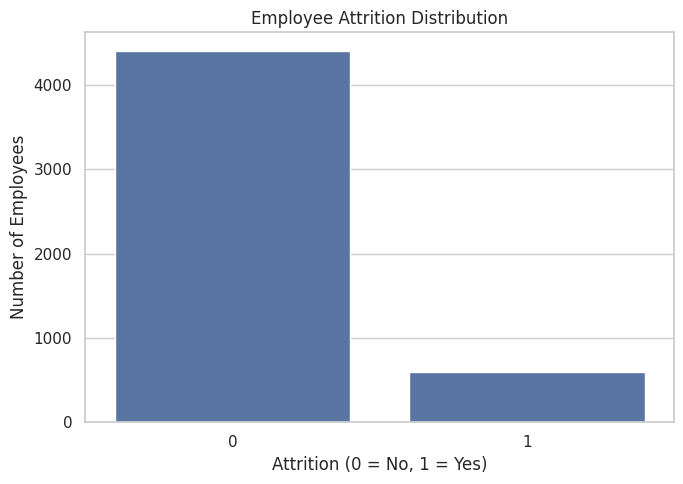

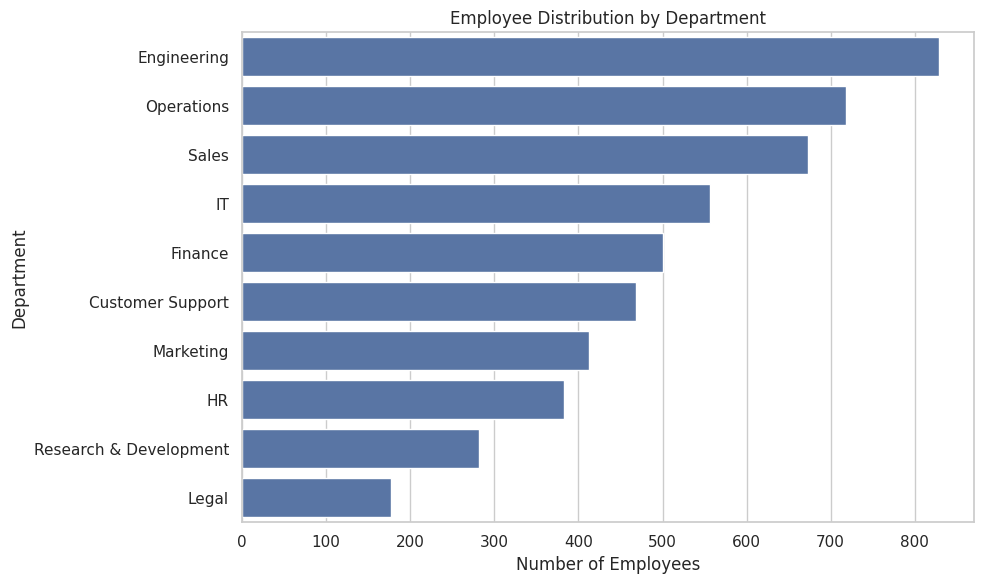

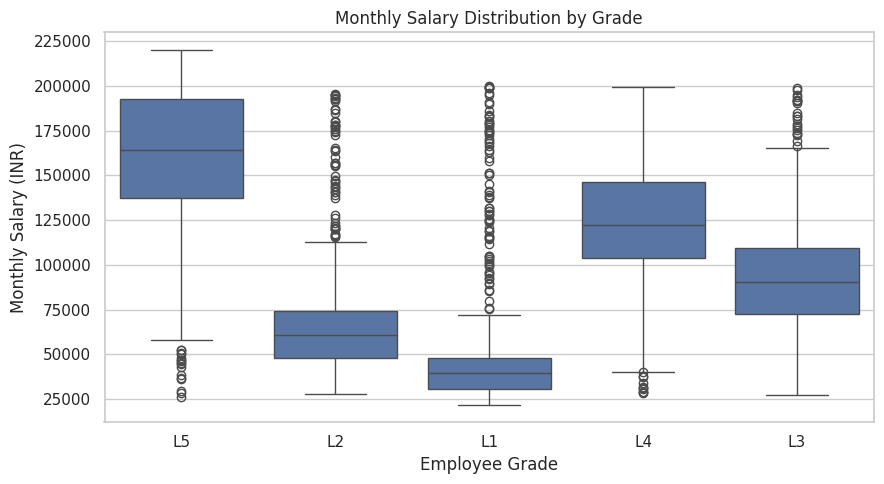

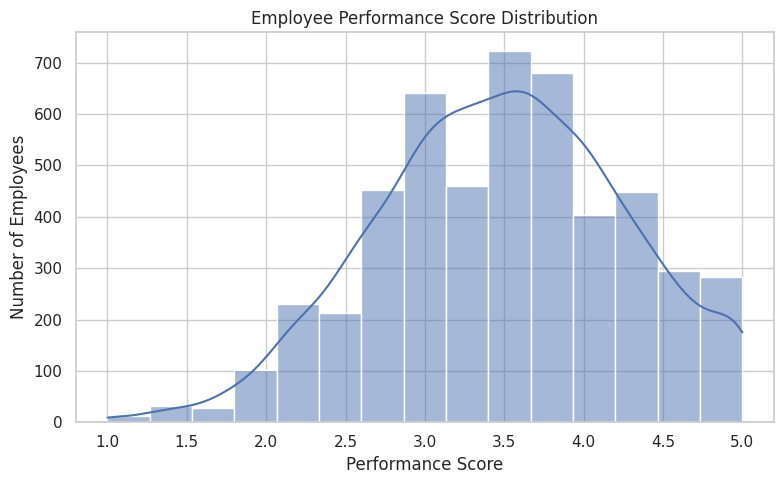

All four charts have been saved to: /content/analysis_results


In [9]:

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

chart_folder = Path("/content/analysis_results")
chart_folder.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(7, 5))
sns.countplot(data=employee_data, x="attrition")
plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition (0 = No, 1 = Yes)")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.savefig(chart_folder / "attrition_distribution.png", dpi=150)
plt.show()
plt.close()

plt.figure(figsize=(10, 6))
department_order = employee_data["department"].value_counts().index
sns.countplot(
    data=employee_data,
    y="department",
    order=department_order
)
plt.title("Employee Distribution by Department")
plt.xlabel("Number of Employees")
plt.ylabel("Department")
plt.tight_layout()
plt.savefig(chart_folder / "department_distribution.png", dpi=150)
plt.show()
plt.close()

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=employee_data,
    x="grade",
    y="monthly_salary_inr"
)
plt.title("Monthly Salary Distribution by Grade")
plt.xlabel("Employee Grade")
plt.ylabel("Monthly Salary (INR)")
plt.tight_layout()
plt.savefig(chart_folder / "salary_by_grade.png", dpi=150)
plt.show()
plt.close()

plt.figure(figsize=(8, 5))
sns.histplot(
    data=employee_data,
    x="performance_score",
    bins=15,
    kde=True
)
plt.title("Employee Performance Score Distribution")
plt.xlabel("Performance Score")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.savefig(chart_folder / "performance_distribution.png", dpi=150)
plt.show()
plt.close()

print("All four charts have been saved to:", chart_folder)


In [7]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/analysis_results",
    "zip",
    "/content/analysis_results"
)

files.download("/content/analysis_results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:

import pandas as pd
from google.colab import files

data_dictionary = pd.DataFrame([
    {
        "column_name": "emp_id",
        "data_type": "String",
        "description": "Unique identifier assigned to each employee",
        "example": "EMP0001"
    },
    {
        "column_name": "department",
        "data_type": "Categorical",
        "description": "Department in which the employee works",
        "example": "Engineering"
    },
    {
        "column_name": "grade",
        "data_type": "Categorical",
        "description": "Employee grade or organizational level",
        "example": "L3"
    },
    {
        "column_name": "join_date",
        "data_type": "Date",
        "description": "Date the employee joined the organization",
        "example": "2025-04-15"
    },
    {
        "column_name": "monthly_salary_inr",
        "data_type": "Numeric",
        "description": "Employee's monthly salary in Indian rupees",
        "example": "85000"
    },
    {
        "column_name": "leave_days_taken",
        "data_type": "Numeric",
        "description": "Number of leave days taken by the employee",
        "example": "8"
    },
    {
        "column_name": "performance_score",
        "data_type": "Numeric",
        "description": "Employee performance score on a 1–5 scale",
        "example": "3.5"
    },
    {
        "column_name": "attrition",
        "data_type": "Binary",
        "description": "Indicates whether the employee left the organization; 1 = Yes, 0 = No",
        "example": "0"
    }
])

data_dictionary.to_csv(
    "/content/data_dictionary.csv", index=False
)

display(data_dictionary)
files.download("/content/data_dictionary.csv")


,column_name,data_type,description,example
0,emp_id,String,Unique identifier assigned to each employee,EMP0001
1,department,Categorical,Department in which the employee works,Engineering
2,grade,Categorical,Employee grade or organizational level,L3
3,join_date,Date,Date the employee joined the organization,2025-04-15
4,monthly_salary_inr,Numeric,Employee's monthly salary in Indian rupees,85000
5,leave_days_taken,Numeric,Number of leave days taken by the employee,8
6,performance_score,Numeric,Employee performance score on a 1–5 scale,3.5
7,attrition,Binary,Indicates whether the employee left the organi...,0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')